Dataset:
    Weight  Height        Class
0       53     163       Normal
1       57     173       Normal
2       58     169       Normal
3       63     165       Normal
4       65     168       Normal
5       65     172       Normal
6       66     177       Normal
7       69     176       Normal
8       72     180       Normal
9       74     182       Normal
10      50     173  Underweight
11      51     167  Underweight
12      52     174  Underweight
13      53     170  Underweight
14      55     180  Underweight
15      58     180  Underweight
16      60     178  Underweight
17      62     183  Underweight
18      68     162   Overweight
19      72     175   Overweight
20      73     164   Overweight
21      75     169   Overweight
22      78     162   Overweight
23      80     180   Overweight
24      82     170   Overweight

Predicted class for [57, 172]: Normal
Name: Fakre alam   Sap_id: 590020990


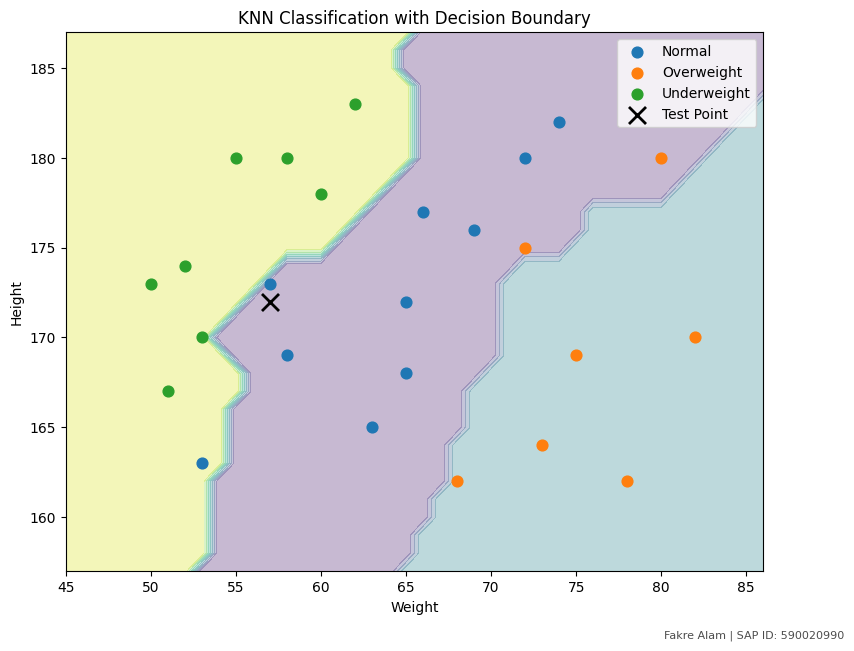

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.preprocessing import LabelEncoder

def euclidean_distance(point1, point2):
    return np.sqrt(np.sum((np.array(point1) - np.array(point2)) ** 2))

def knn_classification(train_data, train_labels, test_point, k):
    distances = []

    for i in range(len(train_data)):
        distance = euclidean_distance(test_point, train_data[i])
        distances.append((distance, train_labels[i]))

    distances.sort(key=lambda x: x[0])

    k_nearest_neighbors = [
        label for _, label in distances[:k]
    ]

    most_common = Counter(k_nearest_neighbors).most_common(1)

    return most_common[0][0]

df = pd.read_csv("knn.csv")

print("Dataset:")
print(df)

data = df.iloc[:, :-1].values
labels = df.iloc[:, -1].values

le = LabelEncoder()
labels_encoded = le.fit_transform(labels)

test_weight = int(input("Enter your weight: "))
test_height = int(input("Enter your height: "))

test_point = [test_weight, test_height]

k = 3

predicted_class = knn_classification(
    data,
    labels,
    test_point,
    k
)

print(f"\nPredicted class for {test_point}: {predicted_class}")
print("Name: Fakre alam   Sap_id: 590020990")
h = 1

x_min = data[:, 0].min() - 5
x_max = data[:, 0].max() + 5
y_min = data[:, 1].min() - 5
y_max = data[:, 1].max() + 5

xx, yy = np.meshgrid(
    np.arange(x_min, x_max, h),
    np.arange(y_min, y_max, h)
)

Z = []

for i in range(len(xx.ravel())):
    point = [xx.ravel()[i], yy.ravel()[i]]

    pred = knn_classification(
        data,
        labels,
        point,
        k
    )

    Z.append(le.transform([pred])[0])

Z = np.array(Z)
Z = Z.reshape(xx.shape)

plt.figure(figsize=(9, 7))

plt.contourf(
    xx,
    yy,
    Z,
    alpha=0.3,
    cmap="viridis"
)

for label in np.unique(labels):
    idx = labels == label

    plt.scatter(
        data[idx, 0],
        data[idx, 1],
        label=label,
        s=60
    )

plt.scatter(
    test_point[0],
    test_point[1],
    color="black",
    marker="x",
    s=150,
    linewidths=2,
    label="Test Point"
)

plt.xlabel("Weight")
plt.ylabel("Height")
plt.title("KNN Classification with Decision Boundary")
plt.figtext(0.99, 0.01, "Fakre Alam | SAP ID: 590020990",
            ha="right", va="bottom",
            fontsize=8, alpha=0.7)

plt.legend()
plt.show()